# CS2 - Carbonate Reservoir Characterization & Rock Typing

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/case_studies/cs2_carbonate_rock_typing_costa.ipynb)

**Case Study - Petrophys Curriculum**

Well **HW-10** (COSTA carbonate dataset, depths in **feet**): the **Kharaib-2** reservoir interval,
with core-corrected porosity and permeability curves.

---

**What you will learn**

- How to calibrate log porosity and saturation against core-derived reference curves - and what
  such a calibration can and cannot prove.
- Why a single porosity-permeability line fails in a carbonate, and how RQI/FZI flow units fix it.
- How to fit a Leverett J-function saturation-height model and cross-check it against log Sw.
- How to turn rock types and net pay into a completion recommendation.

**Prerequisites.** Part A lessons 04 (porosity), 06 (formation water and temperature), 07 (water
saturation), 08 (permeability) and 09 (reservoir quality and net pay); lesson 15 (capillary
pressure) helps for Section 4.5. The base install is enough.

## 1. The brief

> *"We have logged and cored the Kharaib-2 carbonate reservoir interval in well HW-10. Reservoir
> engineering needs a **rock-type profile** and a **reservoir-quality assessment**: where
> are the best flow units, how do porosity and permeability relate, is the interval
> hydrocarbon-bearing, and where should we complete? Calibrate everything to the core so the
> answer is defensible."*

**Who is asking:** the asset team's reservoir engineer, ahead of a completion decision.

**Why it matters.** Carbonates are notoriously heterogeneous: pore geometry (moldic, vuggy,
intercrystalline) decouples porosity from permeability, so a single porosity-permeability
line is meaningless. We must **partition** the rock into flow units (hydraulic flow units /
rock types) using the Amaefule Reservoir Quality Index (RQI) / Flow Zone Indicator (FZI)
framework, calibrate the log petrophysics to the core data, and then rank the reservoir.

**The deliverable (produced by the end of this lesson):**
1. A **rock-type / flow-unit track** vs depth.
2. A **poro-perm cloud** coloured by rock type, with the single transform line and
   constant-FZI reference lines.
3. **Core-vs-log calibration** crossplots (porosity and permeability).
4. A **saturation-height** curve from a fitted Leverett J-function.
5. A **reservoir-quality summary figure + table** and the best intervals to complete.

This case study *chains* many modules; it references the single-module tutorials rather than
re-teaching them.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

In [2]:
import pandas as pd
import petrophys as pp

pd.set_option("display.precision", 3)
pp.list_samples("costa")

['HW-10',
 'HW-24',
 'HW-25',
 'HW-26',
 'HW-27',
 'HW-28',
 'HW-29',
 'HW-3',
 'HW-30',
 'HW-31',
 'HW-32',
 'HW-4',
 'HW-5',
 'HW-6',
 'HW-7',
 'HW-8',
 'HW-9']

## 2. The well & the data

HW-10 is one of 17 wells in the bundled **COSTA** carbonate dataset. Each COSTA LAS file covers
**only the Kharaib-2 reservoir interval**, not the whole well - so "the logged interval" and "the
Kharaib-2" are the same thing here. The bundled `formations_costa` table labels that interval;
we attach it when reading so plots and summaries carry the name.

Let's inventory exactly what we have - measured logs *and* core-derived curves - before planning
the workflow.

In [3]:
well = pp.read(pp.sample("HW-10"), formations=pp.sample("formations_costa"))
pd.DataFrame(well.describe()["curves"])

,mnemonic,unit,description,valid_fraction
0,GR,gAPI,GR,1.000
1,RHOB,g/cm3,RHOB,1.000
2,NPHI,ft3/ft3,NPHI,1.000
3,DT,us/ft,DT,0.000
4,PHIE_CC,ft3/ft3,Core corrected porosity input,1.000
5,RT,ohm.m,RT,1.000
6,SW_INPUT,v/v,Source water saturation input,0.420
7,PERM_CC,mD,Core corrected permeability input,0.816


**Reading the inventory** (`valid_fraction` is the share of the interval each curve covers).

*Wireline logs:* `GR`, `RHOB`, `NPHI`, `RT` are complete. `DT` (sonic) is **all-null** - no
acoustic porosity available here.

*Core-derived curves* (the reason this well was chosen):
- `PHIE_CC` - core-corrected porosity curve (v/v) - per the LAS description a log-resolution
  "core corrected porosity input", not discrete plug measurements
- `PERM_CC` - core-corrected permeability curve (mD, log-resolution), over most of the interval;
  section 4.3 shows its range of several orders of magnitude
- `SW_INPUT` - a source-provided water saturation (fraction) over part of the interval. It is
  **not** a core or SCAL measurement, and it may itself be derived from these logs, so we
  treat it as a reference curve, not as ground truth.

The header carries the Archie parameters, so none has to be invented:

In [4]:
{name: well.get_parameter(name) for name in ["RW", "RWT", "A", "M", "N", "BHT"]}

{'RW': 0.1373, 'RWT': 68.0, 'A': 1.0, 'M': 2.03, 'N': 2.0, 'BHT': 251.0}

`RW` is quoted at `RWT` (degF), `BHT` is in degF. Note **M** - slightly above the classic 2.0,
which is typical for carbonates where cementation reduces pore connectivity.

## 3. Workflow plan (and why in this order)

| # | Step | Call | Why here |
|---|------|------|----------|
| 1 | Interpretation: N-D porosity, Rw at formation temperature, Archie Sw, RQI/FZI, net pay | `pp.interpret` | One auditable run; an **independent** log porosity (PHIT) to calibrate against core |
| 2 | Core-log calibration (porosity, saturation, poro-perm transform) | `core_data_from_well`, `calibrate_porosity`, `calibrate_saturation`, `fit_poro_perm_transform` | Tie the logs to the core-corrected curves; expose the poro-perm scatter |
| 3 | RQI / FZI flow units -> rock types | `FlowUnitModule` | Partition the heterogeneous carbonate into hydraulic flow units |
| 4 | Saturation-height (fit Leverett J) | `petrophys.interpretation.saturation.height` | Physically-based Sw model; cross-check vs log Sw |
| 5 | Net pay with the Costa project cutoffs, and its sensitivity | `formation_summary`, `cutoff_sensitivity` | Turn interpretation into a completion recommendation |

**Why Archie (and not a shaly-sand model)?** Archie's law assumes the rock matrix is a perfect
insulator and all conductivity comes from brine in the pores:

$$S_w^{\,n} = \frac{a\,R_w}{\phi^{m}\,R_t}$$

That assumption holds for a **clean** carbonate (very low GR, negligible clay-bound water).
If GR were high, or if independent evidence showed dispersed clay / conductive minerals, we
would switch to **Waxman-Smits** or **Dual-Water**, which add a clay-conductivity term (CEC /
bound-water) and need inputs the logs do not give (a laboratory CEC with its
counter-ion conductance $B$, or the bound-water resistivity $R_{wb}$), which the interpretation
workflow does not estimate. We keep those in reserve and justify the Archie choice from the
data: the workflow routes every sample of this interval to Archie (section 4.2).

## 4. Execution

### 4.1 One interpretation of the Kharaib-2

`pp.interpret` takes the carbonate settings as keywords:

- `lithology="carbonate"` - the carbonate domain; the matrix is resolved from the logs (limestone
  here, as the warnings report).
- `carbonate_calibration="costa"` - the COSTA field calibration: a **1.1 g/cc brine** for density
  porosity and the mineral volumes (COSTA formation waters are about 200,000 ppm), and illite from GR.
- the **Costa project cutoff set** (`Vcl < 0.30`, `PHIE > 0.10`, `Sw < 0.60`), deliberately tighter
  than the generic carbonate standard because the Kharaib-2 is a high-porosity carbonate and the
  screen targets quality rock; CS3 and lesson 18 use the same set.

The header supplies Rw with its temperature, BHT and the Archie a, m and n. Where density porosity
exceeds neutron porosity by more than 0.05 (crossover), the workflow takes density porosity, the
rule for oil (`hc_type="oil"`, the default; the Kharaib-2 is oil-bearing).

In [5]:
COSTA = dict(lithology="carbonate", carbonate_calibration="costa",
             vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60)
result = pp.interpret(well, **COSTA)
result.warnings

['Input curves PHIE_CC, PERM_CC are used as they stand by every step (SW, BVW, net pay, RQI): the well has no core porosity and no peer-well core to fit its own core model.',
 'Auto lithology resolved via multi_mineral_solver (100% of 363 samples): matrix_type=limestone',
 'Irreducible water saturation assumed 0.20 (none could be picked from the logs): PERM, RQI and FZI rest on that value.']

The first warning matters for everything below: the well has core-corrected `PHIE_CC` and
`PERM_CC`, and the workflow uses them **as they stand** for Sw, BVW, net pay and RQI/FZI. Its own
neutron-density porosity, `PHIT` (limestone matrix, 1.1 g/cc brine), stays on the well as the
**independent** log porosity - essential, because calibrating `PHIE_CC` against itself would be
trivially perfect and tell us nothing. (The assumed Swirr of the last warning only affects the
workflow's own log permeability `PERM`; this study uses `PERM_CC`.)

### 4.2 Water saturation - the Rw temperature correction that makes Archie work

The header quotes `RW = 0.1373 ohm.m` **at RWT = 68 degF** (a lab / surface temperature). Down
at reservoir conditions (BHT 251 degF) brine is far more conductive, so its resistivity is
much lower. The workflow corrects Rw from RWT to the formation temperature at each depth (the
classic **Arps** correction), along a temperature profile built from the BHT. Its decisions:

In [6]:
{name: result.step(name).decisions for name in ["temperature", "rw", "saturation"]}

{'temperature': ['Temperature profile anchored to BHT metadata/input',
  'Gradient = 2.0516 F/100ft (37.39 C/km)',
  'Temp range: 241.2 - 245.1 F'],
 'rw': ['Rw corrected from LAS metadata: 0.1373 ohm.m @ 68F along the temperature profile'],
 'saturation': ['Model selected: archie',
  'Auto-routing: depth-by-depth model selection based on VCLAY and lithology',
  'Depth routing counts: archie=381',
  'Archie coefficients from lithology (config)',
  'No finite source SW input was available; SW is Archie-computed where inputs are finite',
  'Rw range = 0.0408 to 0.0414, Rcl = 5.000 ohm.m',
  'SXO fallback: SXO = SW^(1/5) because RSHA/RXO/RESS and RMF unavailable',
  'Sw range: 0.457 - 1.000']}

The formation is at about 241-245 degF, and the corrected Rw is about 0.041 ohm.m. Every sample
is routed to Archie, with the header's a = 1, m = 2.03, n = 2.

What if the 68 degF Rw were used as it stands? Passing `rw=0.1373` without a temperature does
exactly that (the workflow then takes it at the formation temperature and says so in a warning, and a second warning
in `uncorrected.warnings` reports that this Rw looks too high for the well's own clean, porous rock):

In [7]:
uncorrected = pp.interpret(well, rw=0.1373, **COSTA)
pd.concat({"Rw corrected to formation T": result.formation_summary(),
           "68 degF Rw used as is": uncorrected.formation_summary()}
          )[["Net Reservoir (ft)", "Net Pay (ft)", "Avg Sw", "HCPV"]]

,,Net Reservoir (ft),Net Pay (ft),Avg Sw,HCPV
Rw corrected to formation T,0,152.0,10.5,0.514,1.272
68 degF Rw used as is,0,152.0,0.0,NaN,NaN


Without the correction Rw is about 3.3 times too high, Sw rises by a factor of about 1.8 and the
net pay vanishes: the reservoir is condemned by a units-and-temperature slip, not by the rock.

### 4.3 Core-log calibration

`PHIE_CC` and `PERM_CC` are core-corrected reference curves, not independent raw plug
measurements. Wrapping them in `CoreData` with `core_data_from_well` gives the calibration
functions their reference, but does not make them laboratory ground truth. Three checks:

1. **Porosity:** the log `PHIT` against the core-corrected `PHIE_CC` - bias / RMSE / regression.
2. **Saturation:** the log Archie `SW` against the source-provided `SW_INPUT`.
3. **Poro-perm transform:** fit $\log_{10}(K) = A\,\phi + B$ on the core-corrected samples.

In [8]:
from petrophys.interpretation.core_analysis import (
    calibrate_porosity, calibrate_saturation, core_data_from_well, fit_poro_perm_transform)

core = core_data_from_well(result, porosity_curves=["PHIE_CC"], perm_curves=["PERM_CC"], sw_curves=["SW_INPUT"])
porosity_check = calibrate_porosity(result, core, log_curve="PHIT")
saturation_check = calibrate_saturation(result, core, log_curve="SW")
poro_perm = fit_poro_perm_transform(core, min_perm=0.01)
porosity_check, saturation_check, poro_perm

(CalibrationResult(Porosity (PHIT): n=320, R^2=0.994, bias=0.0047, RMSE=0.0064, log = 1.034*core + -0.0026),
 CalibrationResult(Water saturation (SW): n=160, R^2=0.952, bias=0.1149, RMSE=0.1205, log = 1.003*core + 0.1131),
 PoroPermTransform(log10(K) = 7.14*PHI + (-1.08), R²=0.261, n=310))

**Three very different results - and that is the whole point.**

- **Porosity** ties almost perfectly: R^2 = 0.994, bias +0.005 v/v. Since the reference is
  itself a log-resolution corrected curve rather than independent plug measurements, this is a
  consistency check on the petrophysics rather than an independent core validation - but the two
  porosity sources tell one story.
- **Saturation** tracks `SW_INPUT` closely (R^2 = 0.952), which supports both the Archie choice
  and the Rw correction - but the log reads **higher** by 0.11 on average. `SW_INPUT` is a
  source-provided curve, not a core measurement, so this too is a consistency check, and the
  bias is a caveat we carry forward (section 7).
- The single **poro-perm** transform has R^2 = 0.26: *one* line explains only a small part of the
  permeability variance. In a carbonate, porosity alone does **not** predict permeability -
  pore geometry does. **This is exactly why we need rock typing (Section 4.4).**

Figure 3 shows the porosity calibration and the poro-perm cloud with its single line. The cloud
holds the core-corrected curves, so the axes read "core" for `PHIE_CC` and `PERM_CC`.

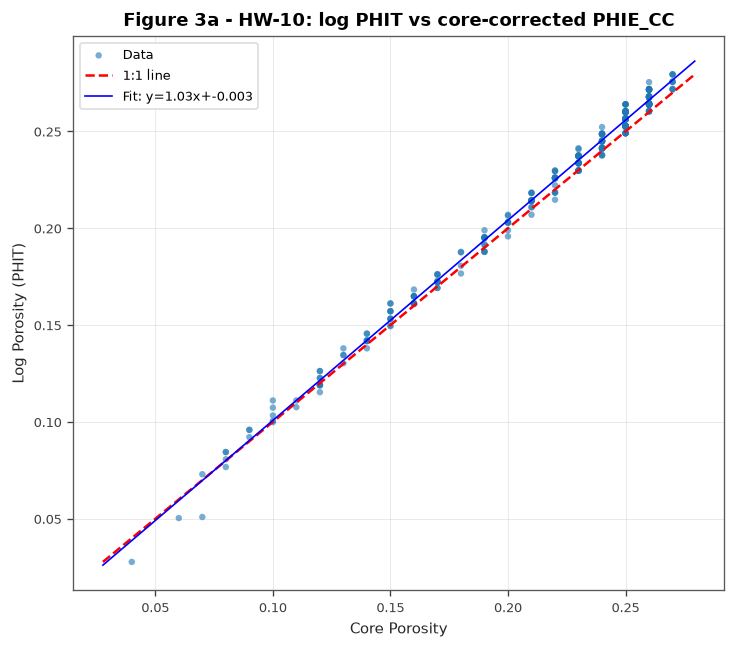

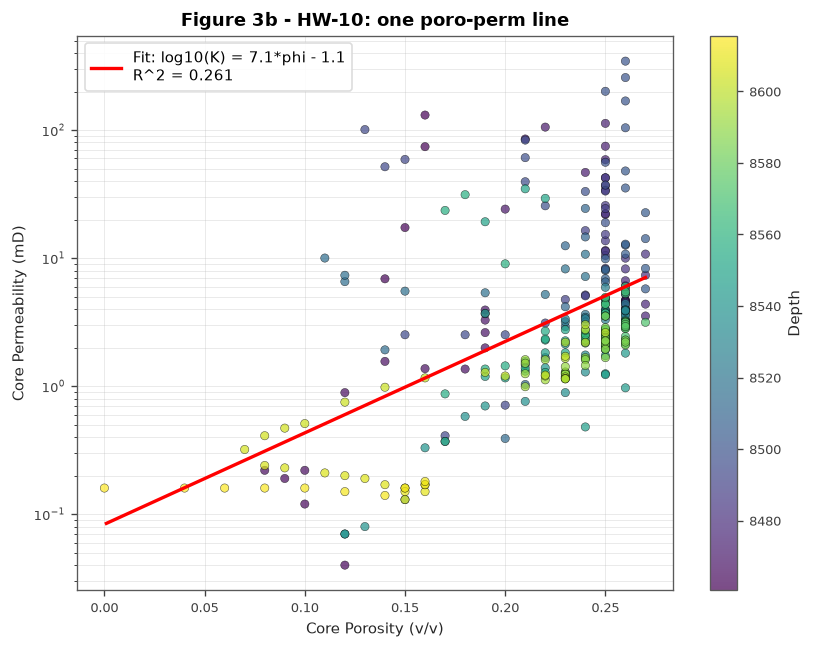

In [9]:
from petrophys.visualization import plot_calibration, plot_poro_perm

plot_calibration(porosity_check, title="Figure 3a - HW-10: log PHIT vs core-corrected PHIE_CC")
plot_poro_perm(core, transform=poro_perm, title="Figure 3b - HW-10: one poro-perm line");

### 4.4 Rock typing - RQI / FZI hydraulic flow units

The Amaefule *et al.* (1993) framework separates the pore-geometry effect from porosity:

$$RQI = 0.0314\sqrt{K/\phi} \quad\text{(um)}, \qquad
\phi_z = \frac{\phi}{1-\phi}, \qquad
FZI = \frac{RQI}{\phi_z}$$

Rock with a **constant FZI** falls on a single straight line in $\log RQI$ vs $\log\phi_z$
space and behaves as one hydraulic flow unit. `FlowUnitModule` computes RQI and FZI from the
well's `PHIE_CC` and the permeability it is given - `PERM_CC` alone here; left to itself it fills the samples
without `PERM_CC` with the workflow's own log permeability - and clusters the samples on log FZI (k-means, at most
four units here) and `add_to_well` writes the unit of each sample as `HFU`, numbered by
increasing FZI: HFU 1 is the poorest rock type, the highest number the best.

In [10]:
from petrophys.evaluation import FlowUnitModule

flow_units = FlowUnitModule(max_units=4)
units = flow_units.calculate(result.well, perm=result.well["PERM_CC"].data)   # core-corrected permeability only
flow_units.add_to_well(result.well, units)      # HFU, and PERM_HFU from each unit's mean FZI
units.summary()

,Samples,Mean FZI
HFU,,
1,190,0.286
2,77,0.581
3,43,1.795


In [11]:
result.well.to_dataframe().query("HFU > 0").groupby("HFU")[["PHIE_CC", "PERM_CC", "FZI"]].median()

,PHIE_CC,PERM_CC,FZI
HFU,,,
1.0,0.24,2.195,0.299
2.0,0.24,5.670,0.574
3.0,0.22,42.400,1.629


The k-means split gives **3 flow units** with mean FZI 0.29, 0.58 and 1.80 um and 190, 77 and 43 samples.
At similar median porosity (0.22-0.24), the median permeability rises from 2.2 mD in HFU 1 to
42 mD in HFU 3 - pore geometry, not porosity, separates them. Samples without `PERM_CC`
have no unit (`HFU` 0) and are left out.

**Figure 1** plots the rock types in the RQI-phi_z plane, with the constant-FZI line of each unit
(dashed); **Figure 2** shows the same samples in the porosity-permeability plane.

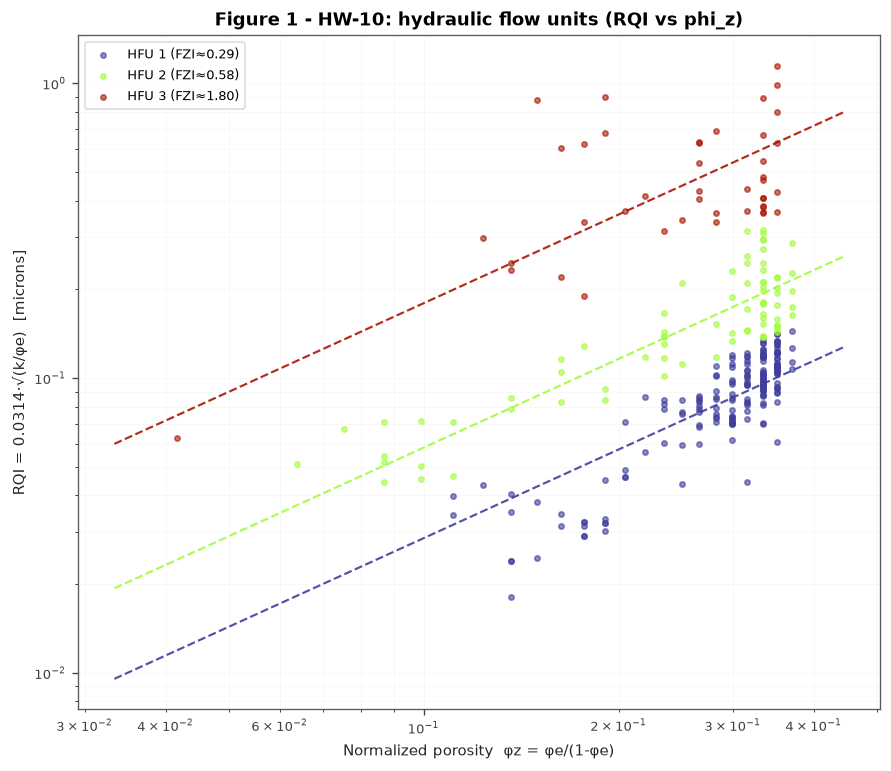

In [12]:
from petrophys.visualization import create_crossplot, create_flow_unit_plot

create_flow_unit_plot(units, title="Figure 1 - HW-10: hydraulic flow units (RQI vs phi_z)");

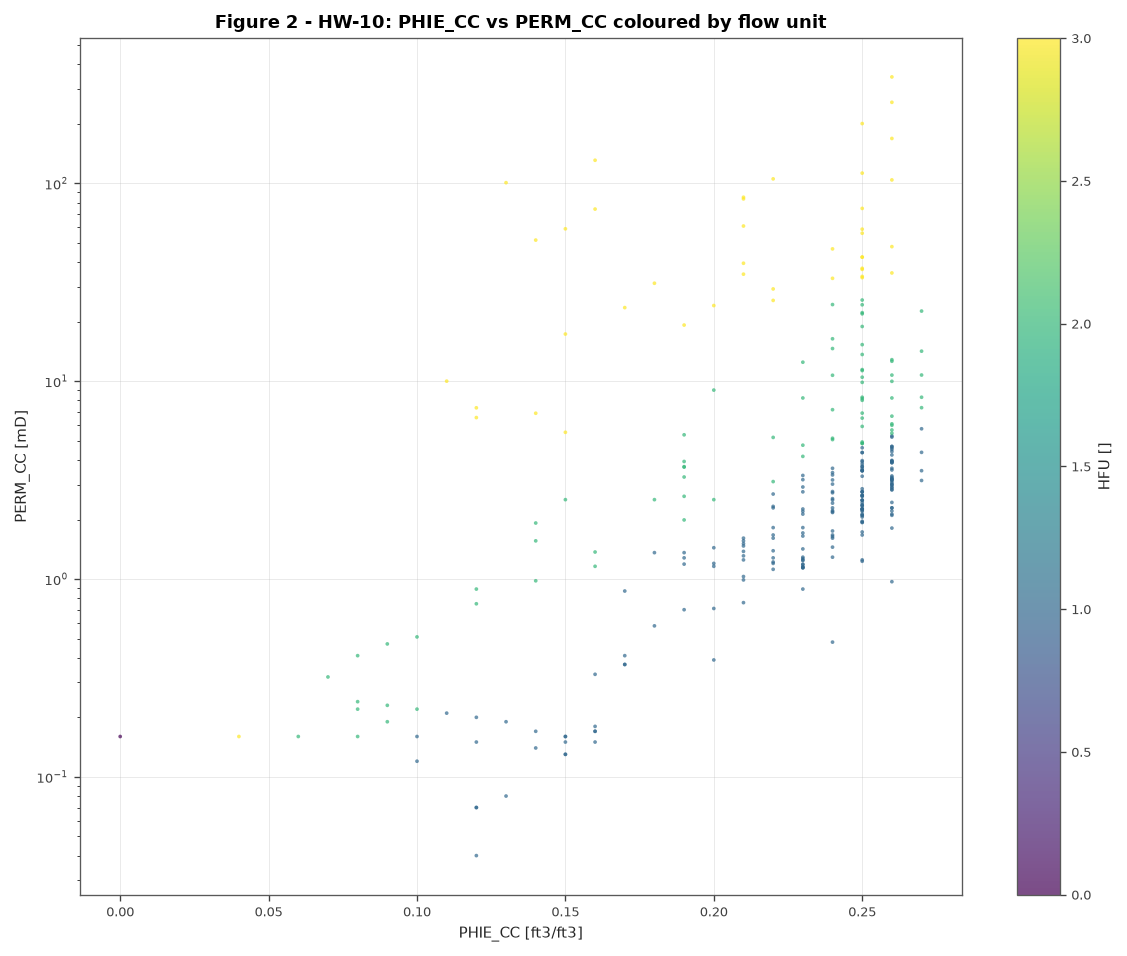

In [13]:
create_crossplot(result, "PHIE_CC", "PERM_CC", color_curve="HFU", y_log=True,
                 title="Figure 2 - HW-10: PHIE_CC vs PERM_CC coloured by flow unit").show()

### 4.5 Saturation-height model (Leverett J-function)

A saturation-height function predicts Sw from *height above the free-water level (FWL)* and
rock quality - independent of resistivity. We fit a Leverett **J-function** that normalises
capillary pressure for permeability and porosity:

$$J = 0.21645\,\frac{P_c}{\sigma\cos\theta}\sqrt{K/\phi}, \qquad S_w = a\,J^{\,b}$$

We have the core-corrected K and phi and the source-provided `SW_INPUT` saturation, but no
laboratory $P_c$, so we reconstruct $P_c$ from **height above a FWL** (buoyancy:
$P_c = 0.433(\rho_w-\rho_{hc})\,h$, oil-brine, interfacial tension 30 dyn/cm, contact angle
30 degrees). `SW_INPUT` covers 8456-8537 ft and approaches ~1 near the base of that coverage, so
we place the FWL just below it, at 8540 ft. The fit is therefore calibrated to a reference
saturation curve, not to capillary-pressure measurements.

Capillary height is vertical. HW-10 has no TVD curve, so the depth index is taken as true
vertical depth - valid for a vertical well only - and the fit and `saturation_height_from_logs`
warn that they do. We treat HW-10 as vertical. `fit_j_function_from_well` builds Pc from the height
and the oil-brine densities, J from Pc, K and phi, and fits the power law in one call.

In [14]:
from petrophys.interpretation.saturation.height import fit_j_function_from_well, saturation_height_from_logs

FWL = 8540.0      # ft, just below the deepest SW_INPUT sample
jmodel = fit_j_function_from_well(result, fwl_depth=FWL, sw_curve="SW_INPUT",
                                  perm_curve="PERM_CC", phi_curve="PHIE_CC")      # oil-brine
jmodel

[temporary directory]\ipykernel_8888\1927008704.py:4: UserWarning: fit_j_function_from_well: no tvd_curve given, so the depth index is taken as true vertical depth, which holds for a vertical well only. Pass tvd_curve, on the datum of fwl_depth, for a deviated well.
  jmodel = fit_j_function_from_well(result, fwl_depth=FWL, sw_curve="SW_INPUT",


JFunctionModel(Sw = 0.4831 * J^-0.1442, R2=0.559, n=151)

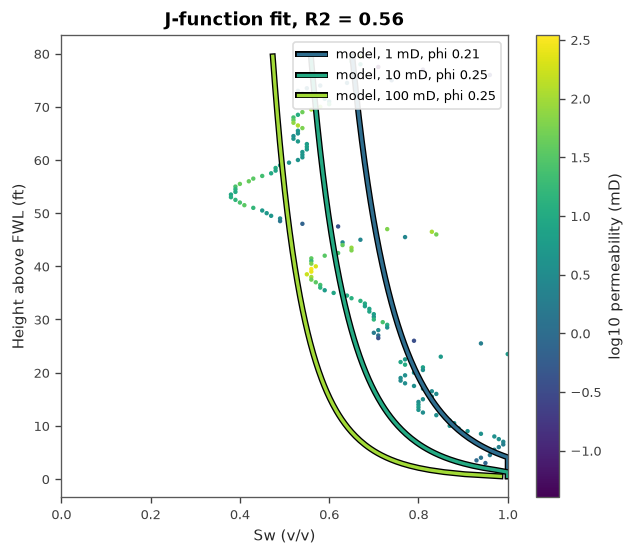

In [15]:
jmodel.plot();

The fitted function is $S_w = 0.483\,J^{-0.144}$, with R^2 = 0.56 on the 151 samples above the FWL
that have K, phi and `SW_INPUT`: the J-function captures the trend of `SW_INPUT` with height and
rock quality, with real scatter around it (Figure 4a, with type curves for three rock qualities).
Applied along the well with each sample's K and phi, it gives a saturation-height Sw curve,
`SW_JH`. Figure 4b draws it against the log Archie Sw and the `SW_INPUT` reference.

[temporary directory]\ipykernel_8888\2367558922.py:1: UserWarning: saturation_height_from_logs: no tvd_curve given, so the depth index is taken as true vertical depth, which holds for a vertical well only. Pass tvd_curve, on the datum of fwl_depth, for a deviated well.
  result.well.add_curve("SW_JH", saturation_height_from_logs(result.well, jmodel, fwl_depth=FWL), unit="v/v")


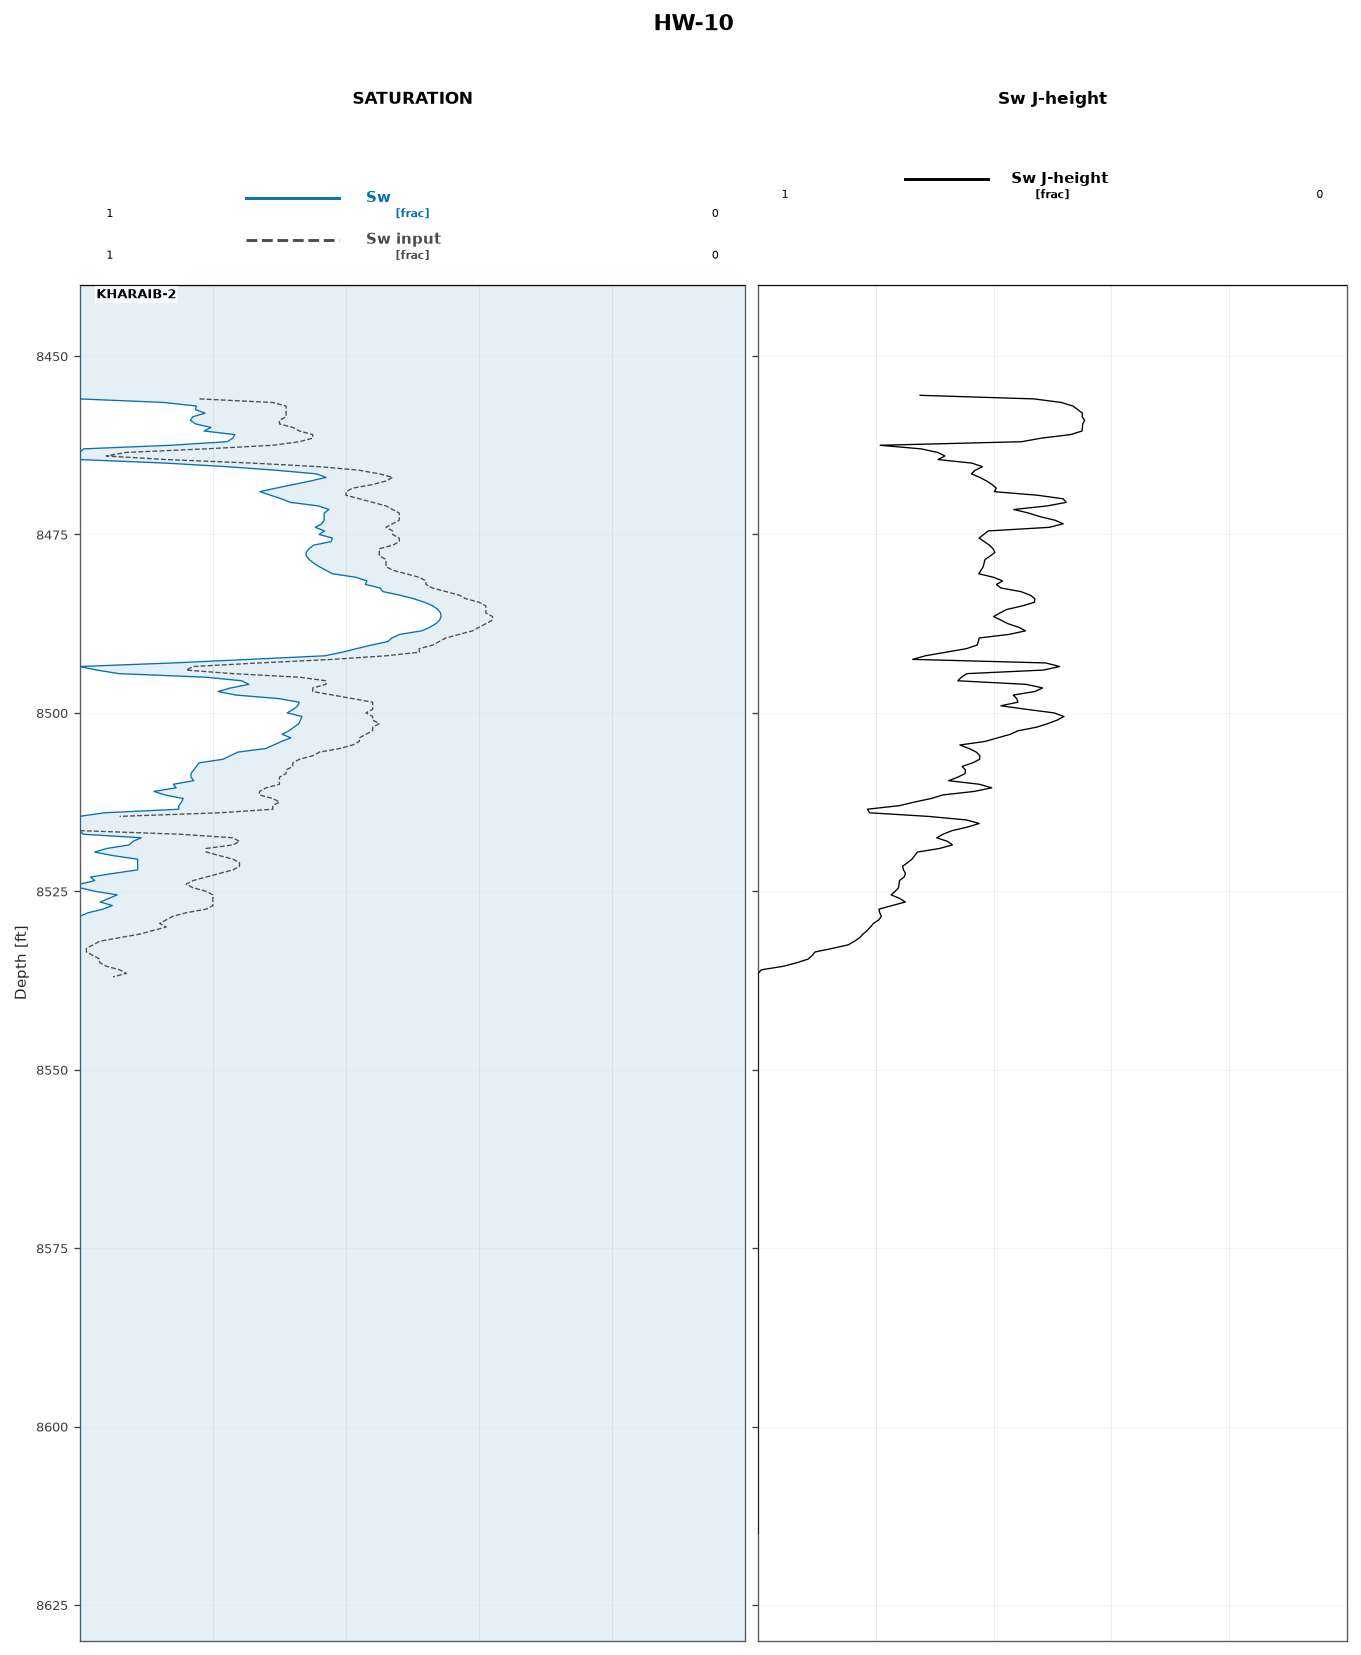

In [16]:
result.well.add_curve("SW_JH", saturation_height_from_logs(result.well, jmodel, fwl_depth=FWL), unit="v/v")
pp.plot(result, curves=["SW", "SW_INPUT", "SW_JH"],
        curve_styles={"SW_JH": {"left": 1, "right": 0, "display_name": "Sw J-height"}}).show()

Between about 8455 and 8525 ft the J-height Sw follows the trend of `SW_INPUT` and the log Sw -
drier near the top, wetter downward - with its own scatter from each sample's K and phi. Towards the
FWL it rises to 1 by construction, and below the FWL every rock type is wet.

### 4.6 Net pay with the Costa project cutoffs

Carbonate cutoffs differ from clastics: clay is negligible (so the Vcl cutoff is loose), but
because low-FZI micro-porosity holds immovable water, a **porosity cutoff** and a **Sw cutoff**
isolate movable-hydrocarbon rock. The interpretation applied the Costa set to every sample, with
porosity from `PHIE_CC` (the first warning in 4.1). The per-formation roll-up gives the answer for
the Kharaib-2:

In [17]:
result.formation_summary()[["Formation", "Top", "Bottom", "Gross (ft)", "Net Reservoir (ft)",
                            "Net Pay (ft)", "Avg PHIE", "Avg Sw", "HCPV"]]

,Formation,Top,Bottom,Gross (ft),Net Reservoir (ft),Net Pay (ft),Avg PHIE,Avg Sw,HCPV
0,KHARAIB-2,8440.0,8630.0,190.5,152.0,10.5,0.249,0.514,1.272


Log Sw reads above `SW_INPUT` (4.3), so how much does net pay depend on the Sw cutoff?
`cutoff_sensitivity` recomputes the flags from the curves for each cutoff, the others held:

In [18]:
from petrophys.evaluation import cutoff_sensitivity

cutoff_sensitivity(result.well, vcl_cutoffs=0.30, phie_cutoffs=0.10, sw_cutoffs=[0.50, 0.60, 0.70],
                   lithology="carbonate")[["sw_cutoff", "net_reservoir_thickness", "net_pay_thickness", "hcpt"]]

,sw_cutoff,net_reservoir_thickness,net_pay_thickness,hcpt
0,0.5,152.0,5.0,0.661
1,0.6,152.0,10.5,1.272
2,0.7,152.0,30.5,2.971


And where is the pay, and which rock types make it up?

In [19]:
result.well.to_dataframe().query("NET_PAY == 1").groupby("HFU")["DEPTH"].agg(["count", "min", "max"])

,count,min,max
HFU,,,
2.0,17,8481.0,8491.0
3.0,4,8483.5,8488.5


## 5. Integrated result - the reservoir-quality panel

One plot of the interpreted well carries the deliverable: GR, the log and core-corrected porosity,
`PERM_CC`, the log Sw against `SW_INPUT`, the FZI, the rock type and the net-pay flag.

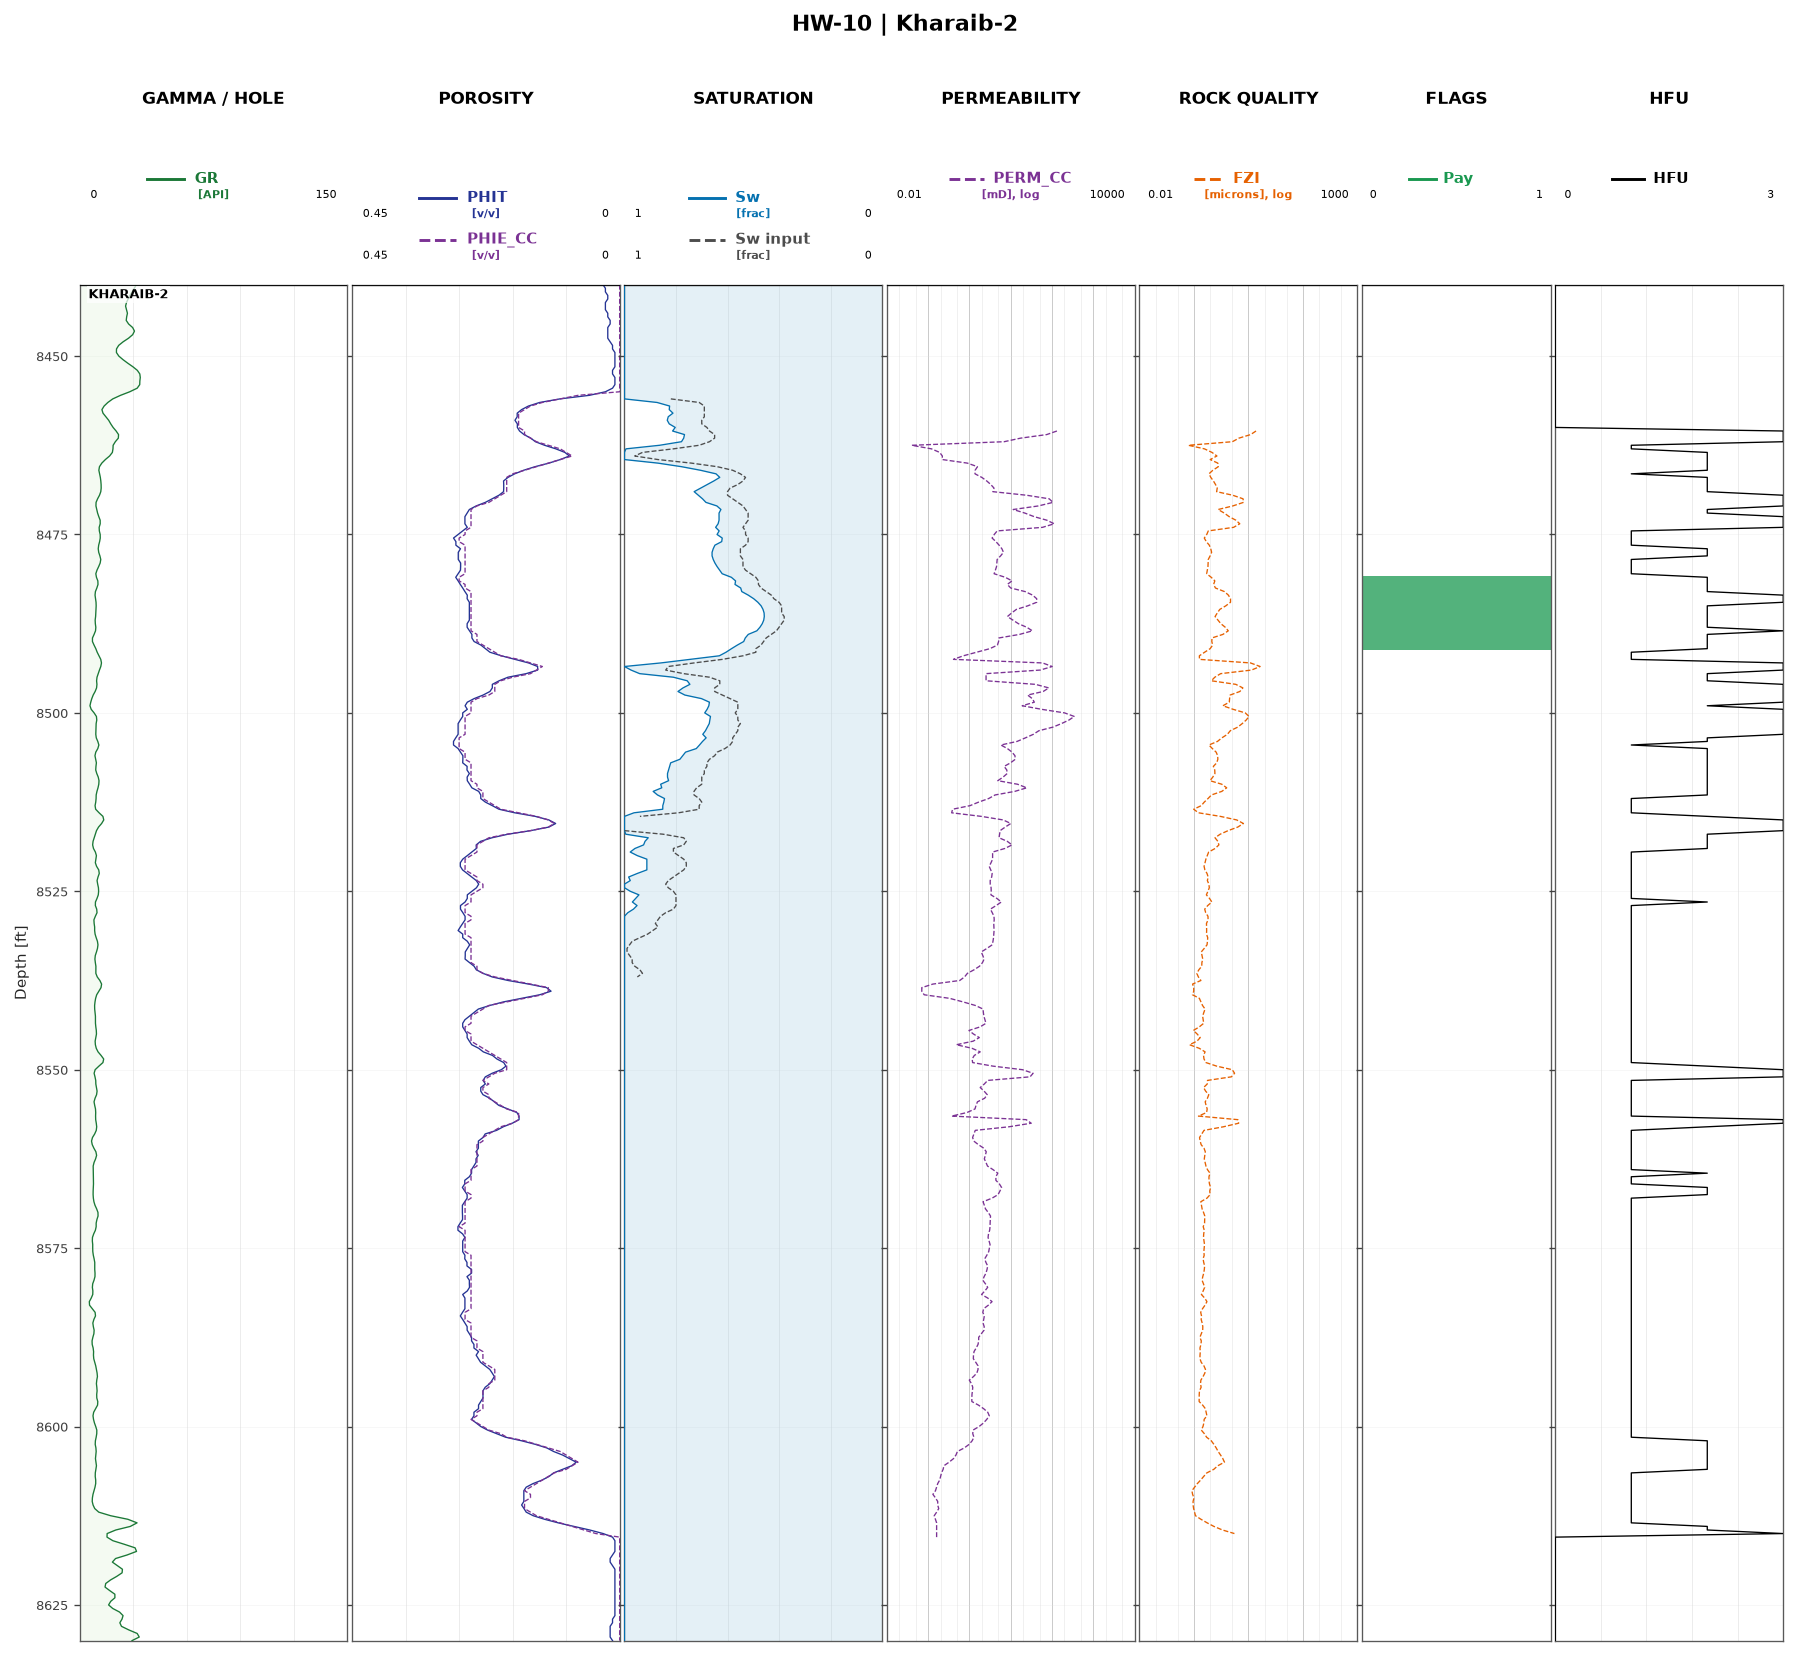

In [20]:
pp.plot(result, curves=["GR", "PHIT", "PHIE_CC", "PERM_CC", "SW", "SW_INPUT", "FZI", "HFU", "NET_PAY"],
        formation_name="Kharaib-2").show()

## 6. Interpretation & deliverable

**Rock-type profile.** The core-corrected curves resolve into 3 hydraulic flow units (the
table in 4.4, HFU 1 poorest to HFU 3 best):

- **HFU 1 (poorest):** the bulk of the samples (190 of 310); porosity comparable to the better rock types
  but low permeability (median 2.2 mD) - classic carbonate **micro-porosity** that stores water but
  does not flow.
- **HFU 2:** permeability rising with FZI at similar porosity (median 5.7 mD).
- **HFU 3 (best):** the sweet spot - median permeability about 20 times HFU 1's at similar
  porosity, indicating better-connected pore geometry (interparticle / intercrystalline, or
  touching vugs). This is the flow unit to prioritise.

**Why porosity alone misled us.** Log porosity ties to the core-corrected porosity curve almost
perfectly (a consistency check), yet a single poro-perm line explains only a small part of the
permeability variance. Permeability - and hence deliverability - is controlled by *pore geometry*,
captured by FZI, not by porosity. Completing on a porosity cutoff alone would target water-filled
micro-porosity.

**Saturation model.** Archie is appropriate (clean carbonate, negligible clay). Once Rw is
temperature-corrected from its 68 degF reference to formation temperature, log Sw tracks the
`SW_INPUT` reference closely. The J-function saturation-height model, calibrated to that same
reference, corroborates the profile above the FWL.

**Deliverable - reservoir-quality assessment of the HW-10 Kharaib-2 interval:**
- Net reservoir 152.0 ft and net pay 10.5 ft of 190.5 ft gross (4.6). Net pay depends
  strongly on the Sw cutoff - 5.0 ft at Sw < 0.50, 30.5 ft at Sw < 0.70 - because this is a
  wet-leaning interval.
- **Where to complete:** the net pay is a thin zone at **8481-8491 ft**, in the upper
  part of the interval and well above the ~8540 ft FWL. It is the only rock that combines a low
  enough Sw with mostly HFU 2 rock (17 of its 21 samples; the other 4 are HFU 3), so it is the completion target. Below the FWL every
  rock type is wet.
- **Best flow unit = HFU 3.** Its high-FZI streaks have the best deliverability; where they sit
  in or next to the pay zone, prioritise them for perforation. Elsewhere they read too wet for the
  Sw cutoff - revisit them if the Sw model or cutoff changes (net pay triples at Sw < 0.70). HFU 1
  micro-porosity intervals, though porous, should be excluded.

## 7. Limitations & assumptions

- **Kharaib-2 only:** the LAS covers only this reservoir interval, so nothing here speaks to
  other zones in the well.
- **No sonic (DT all-null):** could not cross-check porosity with acoustic; the log porosity is
  N-D on a limestone matrix (2.71 g/cc). Dolomite stringers (matrix ~2.87) would bias it.
- **Rw temperature correction is decisive:** using the 68 degF Rw removes all the pay (4.2). The
  correction rests on the header BHT and a linear gradient; an error in BHT propagates directly to Sw.
- **Header Rw and brine salinity disagree:** the header Rw (0.1373 ohm.m at 68 degF) corresponds to
  roughly 50,000 ppm NaCl, far fresher than the ~200,000 ppm brine typical of COSTA formation water
  and assumed for density porosity. A too-fresh Rw raises Archie Sw, which may explain part of the
  log's positive bias against `SW_INPUT`. No cutoff moves the answer as much: with `salinity_ppm=200000`
  in place of the header Rw, net pay is 67 ft instead of 10.5 ft and the log reads 0.20 below `SW_INPUT`
  instead of 0.11 above it (exercise 4). The two waters bracket the reference curve, and the 10.5 ft is
  the low end.
- **Archie assumption:** justified by low GR, but any conductive minerals or significant
  clay-bound water would require **Waxman-Smits** or **Dual-Water** (`sw_model=` with lab `cec`
  and `b_coeff`, or `rwb`) and would lower the computed Sw.
- **No independent saturation truth:** `SW_INPUT` is a source-provided curve, not core or SCAL
  data; both the Archie check and the J-function fit lean on it.
- **Single poro-perm transform is intentionally poor** and must not be used for prediction;
  use the per-rock-type FZI classes (`PERM_HFU`) instead.
- **FWL is inferred** from where `SW_INPUT` -> 1 (~8540 ft), not from pressure (RFT/MDT) data;
  the saturation-height curve inherits that uncertainty.
- **Net-pay porosity is `PHIE_CC`**, the core-corrected curve, as the workflow uses it wherever it
  exists; the log PHIT agrees with it closely here (4.3).
- Rock-type clustering uses **k-means** with `max_units=4`; the data support 3 units. A
  different `n_units`/method would shift boundaries.

## 8. Appendix - reproduce on other wells

Every COSTA well (`pp.list_samples('costa')`) covers the Kharaib-2 interval with the same curve
names and header Archie parameters - except that a few wells lack header `M`/`N`, where the
workflow takes the default exponents (CS3 shows which). `pp.interpret` takes a list of wells with
the same settings and returns one table across them:

In [21]:
wells = pp.read([pp.sample(name) for name in ["HW-10", "HW-3", "HW-24"]], formations=pp.sample("formations_costa"))
pp.interpret(wells, **COSTA).formation_summary()[["Well", "Net Reservoir (ft)", "Net Pay (ft)", "Avg Sw", "HCPV"]]

,Well,Net Reservoir (ft),Net Pay (ft),Avg Sw,HCPV
0,HW-10,152.0,10.5,0.514,1.272
1,HW-3,189.5,189.5,0.100,46.219
2,HW-24,165.0,148.5,0.262,26.943


---
### Recap
- Carbonate reservoir quality is controlled by **pore geometry (FZI)**, not porosity alone.
- **Calibrate to core-derived curves, and know what they are**: porosity ties tightly to the
  core-corrected curve; a single poro-perm line does not - use rock types. `SW_INPUT` is a
  reference curve, not core truth.
- **Temperature-correct Rw** before Archie, or Sw is nonsense: state the temperature of every Rw.
- The deliverable is a **ranked rock-type profile** of the Kharaib-2 interval: the thin upper pay
  zone above the FWL is the completion target, and the best flow unit marks where to perforate
  first.

### Exercises
1. **Matrix sensitivity.** Re-run `pp.interpret` with `matrix_type="dolomite"`. How do the porosity
   calibration and net pay change?
2. **Flow-unit count.** Re-run `FlowUnitModule` with `max_units=3` and `n_units=4`. Which
   boundaries move, and does the best rock type keep the same depths?
3. **FWL uncertainty.** Move the FWL by +/-10 ft and refit the J-function. How much does
   `calibrate_saturation(result.well, core, log_curve="SW_JH")` change?
4. **Brine salinity.** Re-run `pp.interpret(well, salinity_ppm=200000, **COSTA)`. How do net pay and the
   `calibrate_saturation` bias against `SW_INPUT` change, and which Rw would you carry?

### See also / What's next
- Tutorials on porosity, saturation, and reservoir quality for the single-module mechanics.
- **CS3** scales this screening across the Kharaib-2 interval of all 17 COSTA wells.